# Results and Interpretations

---

The notebook:
- reads the classes (`outputs/3_1_clustering/cluster_labels.parquet`), the four tables in `data/2_join_and_roles/` (`descriptors`, `benchmarks`, `markers`, `slicer`) and the state outlines for the map (`data/1_data_notebooks/1_2_tiger/states.gpkg`)
- places the deaths on the US map, per class → <span style="color:yellow">class_map.png</span>
- divides each group's share of the deaths by its share of the residents around them, per race, gender and age band
- divides each tract quintile's share of the deaths by its share of the US residents
- cuts the deaths by the comparison slicer (officer charged), and counts each group's charge rate

<hr style="border:none; border-top:0.5px solid #999">


### Imports and setup

---
- Applies the shared plot style

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from shared.paths import TIGER_DIR, JOIN_ROLES_DIR, OUTPUTS_DIR
from shared.config import SEED
from shared.plotting import setup_plotting, save_fig, CLASS_COLORS, CLASS_DOT_SIZE, CLASS_DOT_ALPHA

setup_plotting()

OUT_DIR = OUTPUTS_DIR / "3_2_results_interpretations"
OUT_DIR.mkdir(parents=True, exist_ok=True)

### Load the inputs

---

In [2]:
labels = pd.read_parquet(OUTPUTS_DIR / "3_1_clustering" / "cluster_labels.parquet")
lca_class = labels["lca_class"]
best_k = len(np.unique(lca_class))


def per_death(name: str) -> pd.DataFrame:
    """The table `name` for every clustered death, in the order of `labels`."""
    table = pd.read_parquet(JOIN_ROLES_DIR / f"{name}.parquet").set_index("mpv_id")
    return table.loc[labels["mpv_id"]].reset_index()


markers = per_death("markers").assign(lca_class=lca_class)
slicer = per_death("slicer")
benchmarks = pd.read_parquet(JOIN_ROLES_DIR / "benchmarks.parquet")
desc = per_death("descriptors").assign(lca_class=lca_class)
print(f"Deaths: {len(desc):,}  |  classes: {best_k}")

Deaths: 7,867  |  classes: 8


### Classes read through their descriptors → <span style="color:yellow">class_map.png</span>

---
- **Read through the median:** age, poverty, population density
- **Read through the share:** male, White, Black, Hispanic, less-lethal also
- **The map draws the 48 contiguous states + DC**

     n_deaths  pct_of_total  median_age  pct_male  pct_white  pct_black  pct_hispanic  pct_less_lethal_also  median_pct_poverty  median_pop_density
0        2418         30.74        35.0     97.18      48.37      27.99         20.03                  1.12               14.50              911.16
1        1598         20.31        33.0     96.99      43.90      34.19         19.23                  0.81               16.10             1000.08
2        1141         14.50        36.0     94.11      51.81      19.56         23.63                 18.19               13.70             1078.02
3         937         11.91        40.0     93.27      69.94      15.95         11.91                  0.64               12.20              610.41
4         694          8.82        33.0     90.74      42.88      30.00         20.76                  8.07               14.60              936.79
5         595          7.56        32.0     92.26      48.69      28.72         20.84                  2.35     

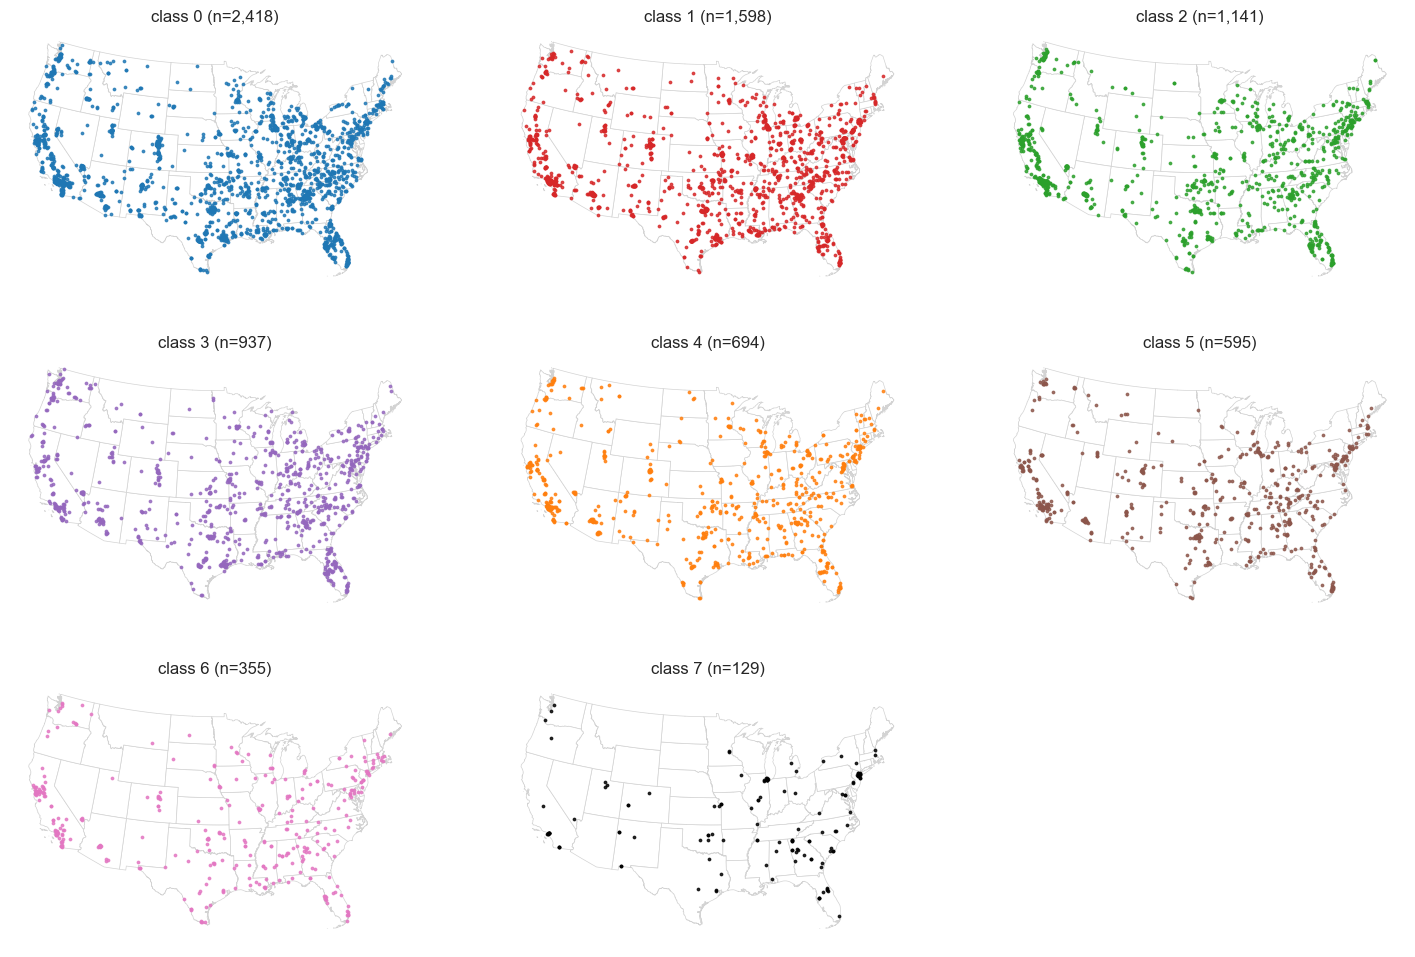

In [3]:
def pct(s, value):
    """Percent of the recorded values of `s` equal to `value`."""
    return (s.dropna() == value).astype(float).mean() * 100.0  # read as floats: a class with no recorded value gives NaN, not <NA>


# a class's descriptors: medians for the numbers, shares for the categories
def describe_class(sub):
    return {
        "n_deaths": len(sub),
        "pct_of_total": len(sub) / len(desc) * 100.0,
        "median_age": sub["age"].median(),
        "pct_male": pct(sub["gender"], "M"),
        "pct_white": pct(sub["race"], "white"),
        "pct_black": pct(sub["race"], "black"),
        "pct_hispanic": pct(sub["race"], "hispanic"),
        "pct_less_lethal_also": pct(sub["less_lethal_also"], True),  # among the shot deaths: a less-lethal force named beside the gunshot
        "median_pct_poverty": sub["pct_poverty"].median(),
        "median_pop_density": sub["pop_density"].median(),
    }


# the classes, then all deaths
class_descriptions = pd.DataFrame({j: describe_class(g) for j, g in desc.groupby("lca_class")}).T
class_descriptions.loc["all"] = describe_class(desc)
print(class_descriptions.round(2).astype({"n_deaths": int}).to_string())

# the map: the state outlines and the deaths on them
states = gpd.read_file(TIGER_DIR / "states.gpkg").to_crs(epsg=5070)  # a flat projection of the US, in meters
# `STUSPS` = the state's two-letter postal code (CA, TX) in the Census file
states = states[~states["STUSPS"].isin(["AK", "HI"])]  # the 48 contiguous states + DC: Alaska and Hawaii would shrink every panel
locations = gpd.points_from_xy(desc["longitude"], desc["latitude"])
deaths_gdf = gpd.GeoDataFrame(desc, geometry=locations, crs="EPSG:4269").to_crs(epsg=5070)  # NAD83, the Census coordinate system the tracts use
deaths_gdf = deaths_gdf[deaths_gdf["state"].isin(states["STUSPS"])]

# one panel per class; the spare panels stay empty
ncols = min(best_k, 3)
nrows = int(np.ceil(best_k / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows))
for j, ax in enumerate(np.ravel(axes)):
    if j >= best_k:
        ax.axis("off")
        continue
    states.plot(ax=ax, color="white", edgecolor="lightgray", linewidth=0.5)
    deaths_gdf[deaths_gdf["lca_class"] == j].plot(ax=ax, markersize=CLASS_DOT_SIZE, color=CLASS_COLORS[j], alpha=CLASS_DOT_ALPHA)  # the same dot as in the MDS picture
    ax.set_title(f"class {j} (n={(lca_class == j).sum():,})")
    ax.axis("off")
save_fig(fig, "class_map", OUT_DIR)

### Local benchmark

---
- **The ratio:** a category's share of the deaths with that variable recorded ÷ its tract share averaged over the deaths, for race, gender (`M`, `F`) and age band, over all deaths and per class
- **Each ratio comes with a 95% interval from the bootstrap:** the deaths are redrawn with replacement 1,000 times, each redraw giving the race, gender and age ratios together; the middle 95% of the redrawn ratios is the interval. A ratio whose interval contains 1 cannot be read as above or below the category's share
- **Residents include children and people who never meet the police,** so a ratio says "more than their share of the neighborhood", not "more than their share of police encounters"

In [4]:
N_BOOT = 1_000  # bootstrap redraws per group

# the benchmark columns are named `<dimension> = <category>`, e.g. `race = black`
share_cols = [col for col in benchmarks.columns if " = " in col]
desc = desc.merge(benchmarks[["tract_id", *share_cols]], on="tract_id", how="left")  # every death kept


def ratio(deaths, col):
    """The category's share of the deaths with its dimension recorded ÷ its tract share averaged over the deaths."""
    dimension, category = col.split(" = ")
    recorded = deaths[dimension].dropna()
    death_share = (recorded == category).sum() / len(recorded) * 100
    return death_share / deaths[col].mean()


def ratio_rows(group, deaths, rng):
    """Every benchmark column's deaths, ratio and 95% interval."""
    # the ratio on the real deaths
    point = {col: ratio(deaths, col) for col in share_cols}

    # the bootstrap: the same ratio on `N_BOOT` redraws
    redraws = []
    for _ in range(N_BOOT):
        redraw = deaths.iloc[rng.integers(0, len(deaths), len(deaths))]  # the deaths, drawn with replacement
        redraws.append({col: ratio(redraw, col) for col in share_cols})
    redraws = pd.DataFrame(redraws)

    # one row per category: deaths, ratio and interval
    rows = []
    for col in share_cols:
        dimension, category = col.split(" = ")
        n = (deaths[dimension] == category).sum()
        low, high = redraws[col].quantile([0.025, 0.975])  # the middle 95% of the redrawn ratios
        rows.append({"group": group, "dimension": dimension, "category": category, "deaths_n": n,
                     "ratio (interval)": f"{point[col]:.2f} ({low:.2f}-{high:.2f})" if n else "n/a"})
    return rows


# all deaths first, then each class
rng = np.random.default_rng(SEED)
groups = [("all", desc)]
for j, sub in desc.groupby("lca_class"):
    groups.append((f"class {j}", sub))

rows = []
for group, deaths in groups:
    rows += ratio_rows(group, deaths, rng)
all_ratios = pd.DataFrame(rows)
shown = ["deaths_n", "ratio (interval)"]

# race first, then gender and age band
race = all_ratios[all_ratios["dimension"] == "race"].rename(columns={"category": "race"})
print(race.set_index(["race", "group"])[shown].sort_index().to_string())
print()
others = all_ratios[all_ratios["dimension"] != "race"]
print(others.set_index(["dimension", "category", "group"])[shown].to_string())

                  deaths_n  ratio (interval)
race     group                              
AIAN     all           138  1.50 (1.29-1.74)
         class 0        45  1.64 (1.26-2.06)
         class 1        22  1.18 (0.75-1.72)
         class 2        23  1.90 (1.22-2.76)
         class 3         8  0.94 (0.37-1.58)
         class 4        27  1.93 (1.36-2.78)
         class 5         7  1.19 (0.51-2.10)
         class 6         6  1.69 (0.65-3.07)
         class 7         0               n/a
asian    all           126  0.41 (0.34-0.49)
         class 0        37  0.41 (0.29-0.57)
         class 1        19  0.34 (0.20-0.51)
         class 2        31  0.54 (0.35-0.73)
         class 3        11  0.35 (0.17-0.60)
         class 4        15  0.51 (0.26-0.78)
         class 5         3  0.12 (0.00-0.27)
         class 6         9  0.54 (0.20-0.89)
         class 7         1  0.28 (0.00-0.87)
black    all          2030  1.71 (1.66-1.77)
         class 0       636  1.73 (1.63-1.84)
         c

### National benchmark

---
- **Quintile 1 holds the lowest values:** the lowest poverty shares, the most Black-concentrated tracts
- **The ratio:** a quintile's share of the deaths ÷ its actual share of the US residents (a tract goes whole into one quintile, so a quintile is not exactly 20%)
- **Tracts without a value are left out,** with their residents and their deaths
- **The 95% interval comes from bootstrapping the deaths;** the residents are a full count
- **Race segregation is the ICE for race (Krieger et al., 2016):** the share of White residents minus the share of Black residents, +1 = every resident is White, -1 = Black; a tract that is 70% White and 10% Black scores 0.6

In [5]:
MEASURES = ["pct_poverty", "race_segregation"]
FIFTHS = [1, 2, 3, 4, 5]


def fifth_ratios(death_fifths, resident_share):
    """Each fifth's share of the deaths ÷ its share of the US residents."""
    death_share = death_fifths.value_counts().reindex(FIFTHS, fill_value=0) / len(death_fifths)
    return death_share / resident_share


def fifth_rows(measure, group, deaths, rng):
    """Each fifth's ratio and 95% interval, for these deaths."""
    # the tracts in a fifth, and each fifth's share of the US residents
    in_a_fifth = benchmarks[benchmarks[f"fifth_{measure}"].notna()]
    fifth_of_tract = in_a_fifth.set_index("tract_id")[f"fifth_{measure}"]
    resident_share = in_a_fifth.groupby(f"fifth_{measure}")[f"fifth_share_{measure}"].first()
    death_fifths = deaths["tract_id"].map(fifth_of_tract).dropna()  # the deaths whose tract sits in a fifth

    # the ratio on the real deaths
    point = fifth_ratios(death_fifths, resident_share)

    # the bootstrap: the same ratio on `N_BOOT` redraws
    redraws = []
    for _ in range(N_BOOT):
        redraw = death_fifths.iloc[rng.integers(0, len(death_fifths), len(death_fifths))]  # drawn with replacement
        redraws.append(fifth_ratios(redraw, resident_share))
    redraws = pd.DataFrame(redraws)

    # one row per fifth: ratio and interval
    rows = []
    for fifth in FIFTHS:
        low, high = redraws[fifth].quantile([0.025, 0.975])  # the middle 95% of the redrawn ratios
        rows.append({"measure": measure, "group": group, "fifth": fifth,
                     "ratio (interval)": f"{point[fifth]:.2f} ({low:.2f}-{high:.2f})"})
    return rows


# every measure, for all deaths and each class
rng_fifths = np.random.default_rng(SEED)  # its own redraws, so the local benchmark's stay as they were
rows = []
for measure in MEASURES:
    for group, deaths in groups:
        rows += fifth_rows(measure, group, deaths, rng_fifths)
fifths = pd.DataFrame(rows)
print(fifths.pivot(index=["measure", "group"], columns="fifth", values="ratio (interval)").to_string())

print()
# the tracts and deaths without a fifth
for measure in MEASURES:
    in_a_fifth = benchmarks[f"fifth_{measure}"].notna()
    tracts_left_out = (~in_a_fifth).sum()
    deaths_left_out = (~desc["tract_id"].isin(benchmarks.loc[in_a_fifth, "tract_id"])).sum()
    print(f"{measure}: {tracts_left_out:,} tracts, {deaths_left_out} deaths left out")

fifth                                    1                 2                 3                 4                 5
measure          group                                                                                            
pct_poverty      all      0.48 (0.45-0.52)  0.65 (0.61-0.69)  0.94 (0.89-0.98)  1.20 (1.15-1.25)  1.73 (1.68-1.78)
                 class 0  0.51 (0.46-0.58)  0.66 (0.59-0.73)  0.87 (0.79-0.95)  1.18 (1.09-1.27)  1.78 (1.68-1.88)
                 class 1  0.36 (0.30-0.42)  0.63 (0.55-0.70)  0.86 (0.77-0.96)  1.20 (1.10-1.30)  1.95 (1.84-2.07)
                 class 2  0.52 (0.43-0.60)  0.67 (0.57-0.76)  0.97 (0.85-1.09)  1.19 (1.07-1.32)  1.65 (1.52-1.79)
                 class 3  0.60 (0.50-0.71)  0.77 (0.67-0.89)  1.14 (1.00-1.27)  1.22 (1.08-1.36)  1.27 (1.13-1.40)
                 class 4  0.47 (0.36-0.59)  0.55 (0.43-0.66)  0.97 (0.82-1.12)  1.23 (1.07-1.38)  1.79 (1.61-1.97)
                 class 5  0.48 (0.37-0.59)  0.68 (0.54-0.82)  0.95 (0.81-1.11)  

pct_poverty: 996 tracts, 30 deaths left out


race_segregation: 798 tracts, 24 deaths left out


### Comparison slicer

---
Cuts the deaths into two slices, charged yes and no, compared on race, armed status, mental state, gender, less-lethal also and the class.

- **Charge rates:** how many of each group's deaths were charged, by gender, race, armed status, less-lethal also and class, and by gender and race within armed and unarmed

In [6]:
# the deaths with officer charged recorded
sliced = markers.join(slicer["officer_charged"])
sliced = sliced[sliced["officer_charged"].notna()]
sliced["charged"] = sliced["officer_charged"] == "yes"

# the markers' shares in the two slices, and the recorded n
for col in ["race", "allegedly_armed", "signs_of_mental_illness", "gender", "less_lethal_also", "lca_class"]:
    shares = pd.crosstab(sliced[col], sliced["officer_charged"], normalize="columns") * 100
    print(shares[["yes", "no"]].round(2).to_string())
    print("recorded n:", sliced.dropna(subset=[col])["officer_charged"].value_counts().reindex(["yes", "no"]).to_dict(), "\n")

# the charge rate of each group
print(f"Charged: {sliced['charged'].sum():,} of {len(sliced):,} deaths ({sliced['charged'].mean() * 100:.2f}%)", "\n")
for by in ["gender", "race", "allegedly_armed", "less_lethal_also", "lca_class", ["allegedly_armed", "gender"], ["allegedly_armed", "race"]]:
    rates = sliced.groupby(by)["charged"].agg(deaths_n="size", charged_n="sum", pct_charged="mean")
    rates["pct_charged"] *= 100
    print(rates.round(2).to_string(), "\n")

officer_charged    yes     no
race                         
AIAN              1.73   1.87
asian             1.73   1.70
black            43.29  26.74
hispanic         14.72  19.87
white            38.53  49.82
recorded n: {'yes': 231, 'no': 7180} 

officer_charged    yes     no
allegedly_armed              
armed            28.44  85.65
unarmed          71.56  14.35
recorded n: {'yes': 218, 'no': 7043} 

officer_charged            yes     no
signs_of_mental_illness              
drugs or alcohol          7.44   4.79
mental illness           13.02  24.08
neither                  79.53  71.13
recorded n: {'yes': 215, 'no': 6811} 

officer_charged    yes     no
gender                       
F                21.12   4.63
M                78.88  95.37
recorded n: {'yes': 232, 'no': 7600} 

officer_charged     yes     no
less_lethal_also              
False             96.36  95.48
True               3.64   4.52


recorded n: {'yes': 165, 'no': 7207} 

officer_charged    yes     no
lca_class                    
0                 6.87  31.52
1                 6.44  20.76
2                 9.44  14.68
3                 2.58  12.21
4                33.48   8.02
5                12.02   7.43
6                12.45   4.22
7                16.74   1.14
recorded n: {'yes': 233, 'no': 7614} 

Charged: 233 of 7,847 deaths (2.97%) 

        deaths_n  charged_n  pct_charged
gender                                  
F            401         49        12.22
M           7431        183         2.46 

          deaths_n  charged_n  pct_charged
race                                      
AIAN           138          4         2.90
asian          126          4         3.17
black         2020        100         4.95
hispanic      1461         34         2.33
white         3666         89         2.43 

                 deaths_n  charged_n  pct_charged
allegedly_armed                                  
armed         

                        deaths_n  charged_n  pct_charged
allegedly_armed gender                                  
armed           F            260          9         3.46
                M           5823         53         0.91
unarmed         F            125         39        31.20
                M           1039        116        11.16 

                          deaths_n  charged_n  pct_charged
allegedly_armed race                                      
armed           AIAN            89          1         1.12
                asian          100          2         2.00
                black         1542         27         1.75
                hispanic      1102          8         0.73
                white         2902         23         0.79
unarmed         AIAN            26          3        11.54
                asian           20          1         5.00
                black          357         63        17.65
                hispanic       227         26        11.45
       